The goal of this project is to explore "radio frequency interference" (RFI) of HERA data and clean up the data. The background should be a constant, so any fluctuations above that are worth exploring. Honestly, I need to figure out a lot more about what the waterfall plots show and how the pyuvdata package works!

In [1]:
from pyuvdata import UVData
from astropy.time import Time
import os

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

import plotly.graph_objects as go

plt.rcParams['figure.figsize'] = [14, 6]

In [2]:
uvd = UVData.from_file("zen.2459122.34011.mini.sum.uvh5")

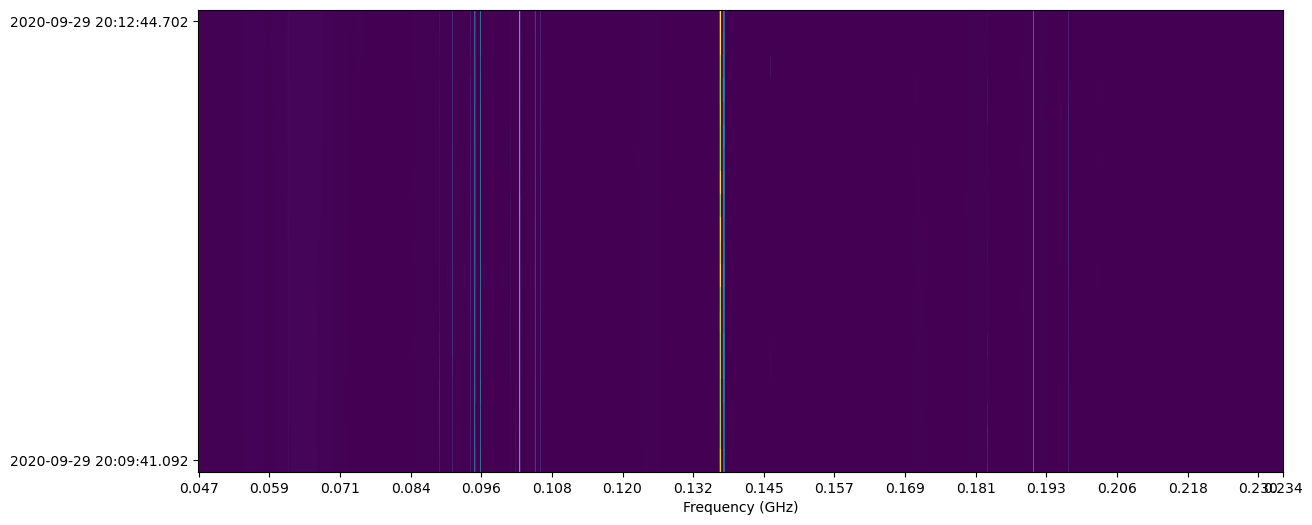

In [3]:
#Antenna pair 1, 2
waterfall_data = uvd.get_data((1, 2, uvd.polarization_array[0]))
waterfall_times = Time(uvd.get_times((1, 2, uvd.polarization_array[0])), format="jd").iso

fig, ax = plt.subplots(1, 1)
_ = ax.imshow(np.abs(waterfall_data), interpolation="none", origin="lower", aspect="auto")
_ = ax.set_yticks([0, waterfall_times.size - 1])
_ = ax.set_yticklabels([waterfall_times[0], waterfall_times[-1]])
freq_tick_inds = np.concatenate((np.arange(0, uvd.Nfreqs, 100), [uvd.Nfreqs-1]))
_ = ax.set_xticks(freq_tick_inds)
_ = ax.set_xticklabels([f"{val:.3f}" for val in uvd.freq_array[freq_tick_inds]*1e-9])
_ = ax.set_xlabel("Frequency (GHz)")

plt.show()

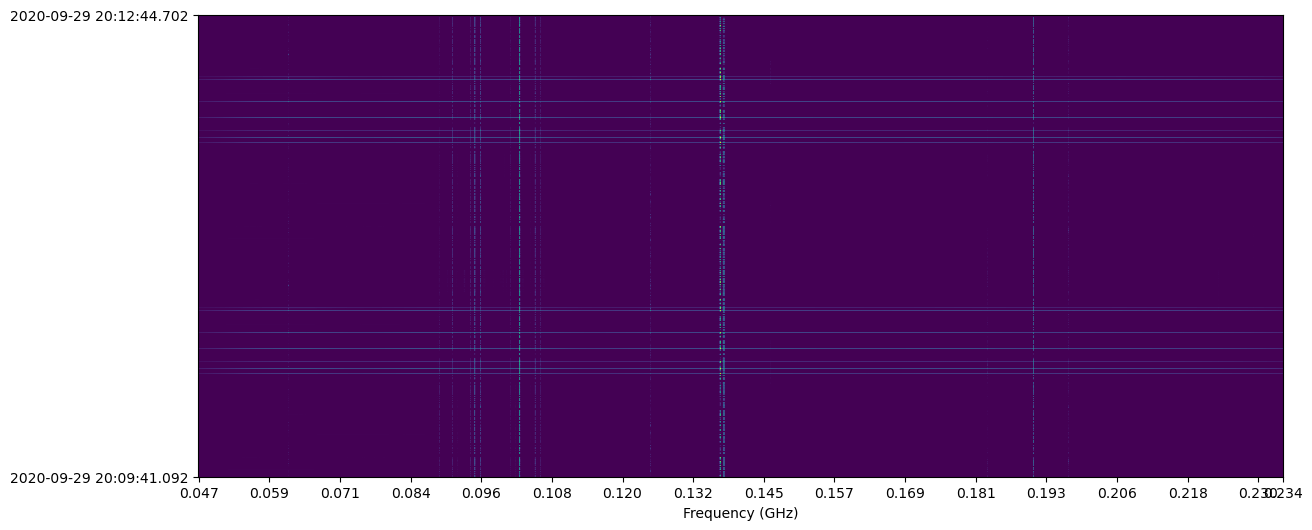

In [4]:
#All baselines
waterfall_data = uvd.get_data(uvd.polarization_array[0])
waterfall_times = Time(uvd.get_times(uvd.polarization_array[0]), format="jd").iso

fig, ax = plt.subplots(1, 1)
_ = ax.imshow(np.abs(waterfall_data), interpolation="none", origin="lower", aspect="auto")
_ = ax.set_yticks([0, waterfall_times.size - 1])
_ = ax.set_yticklabels([waterfall_times[0], waterfall_times[-1]])
freq_tick_inds = np.concatenate([np.arange(0, uvd.Nfreqs, 100), [uvd.Nfreqs - 1]])
_ = ax.set_xticks(freq_tick_inds)
_ = ax.set_xticklabels([f"{val:.3f}" for val in uvd.freq_array[freq_tick_inds] * 1e-9])
_ = ax.set_xlabel("Frequency (GHz)")

plt.show()

divide by zero encountered in log


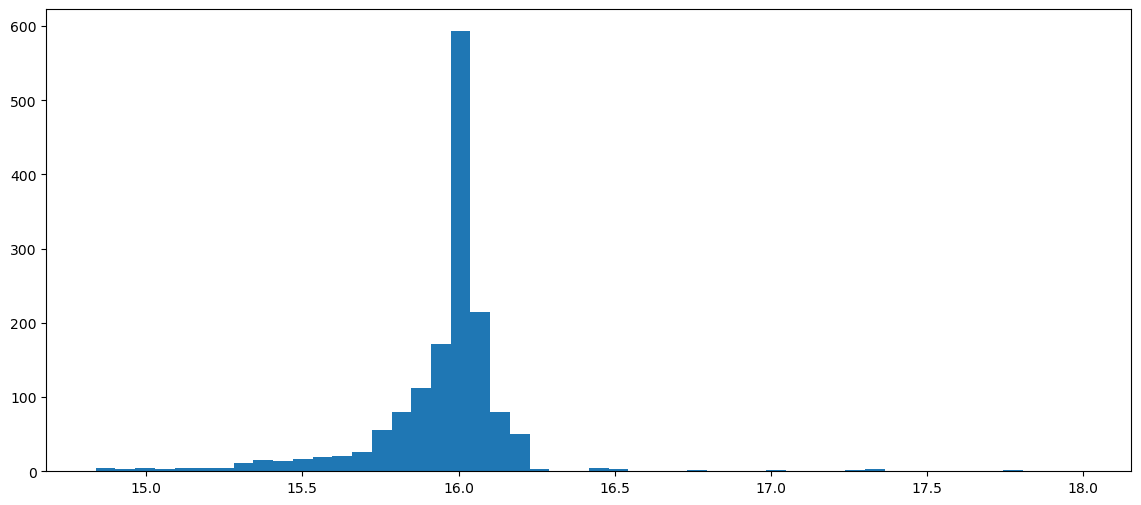

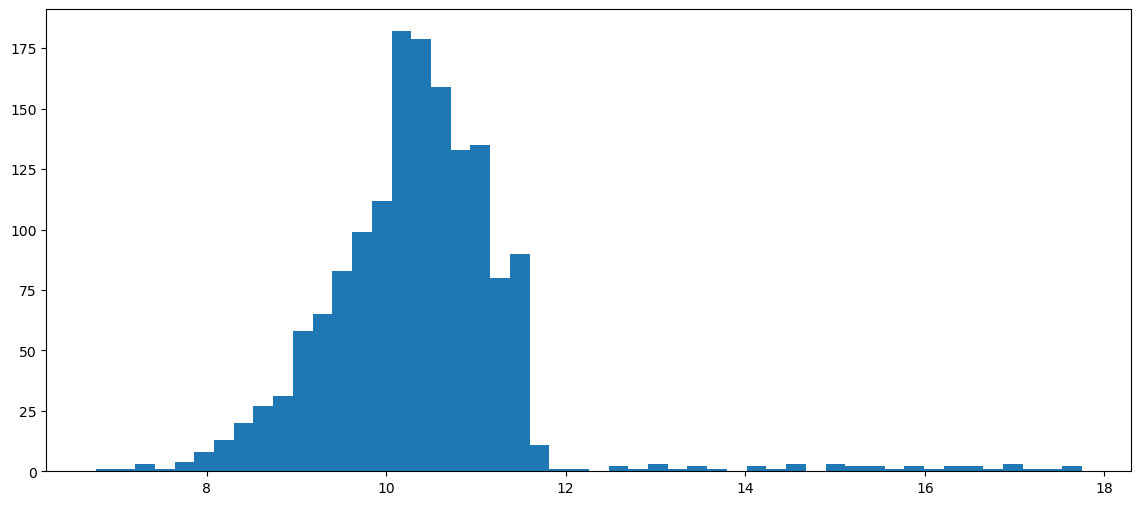

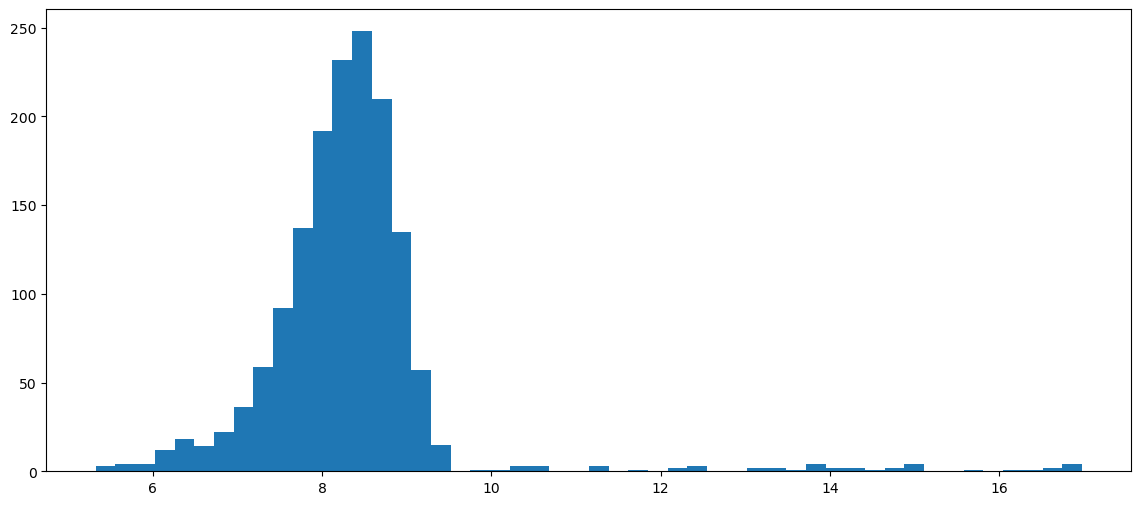

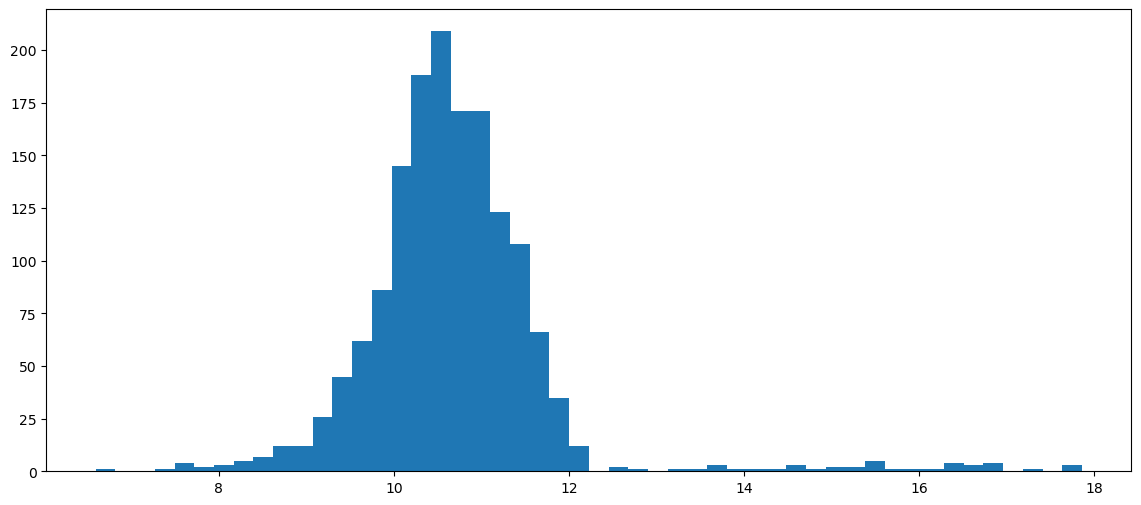

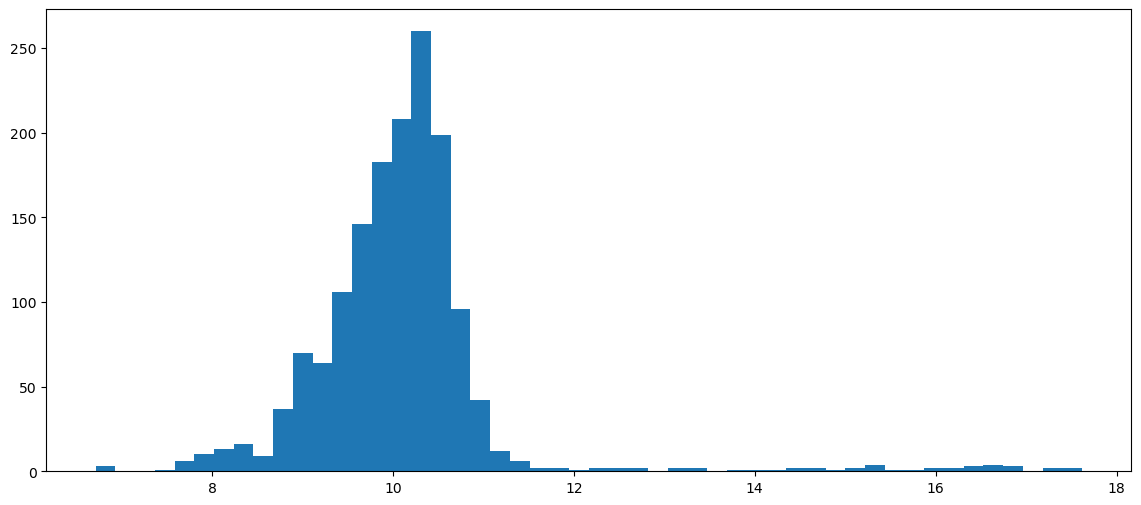

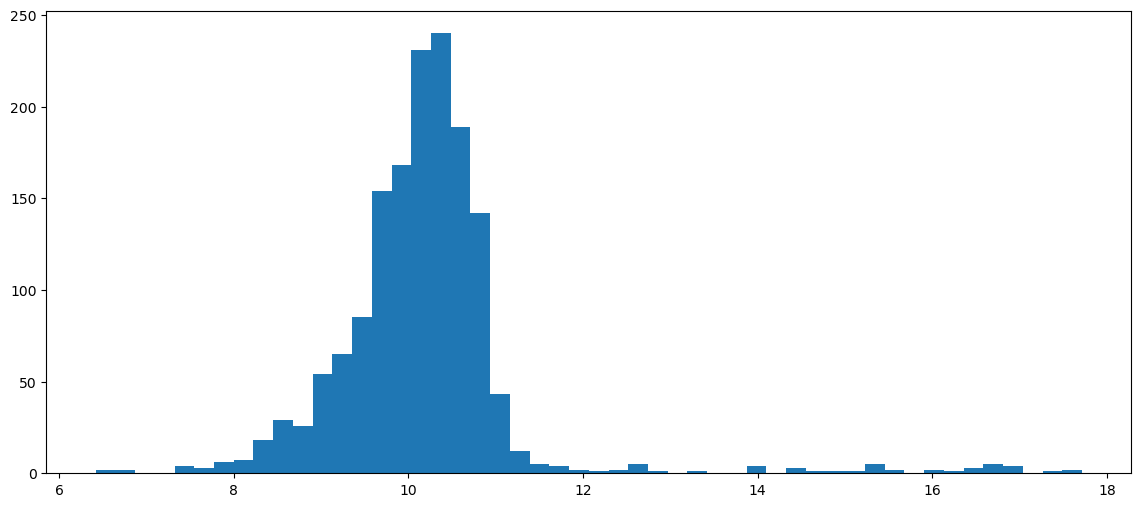

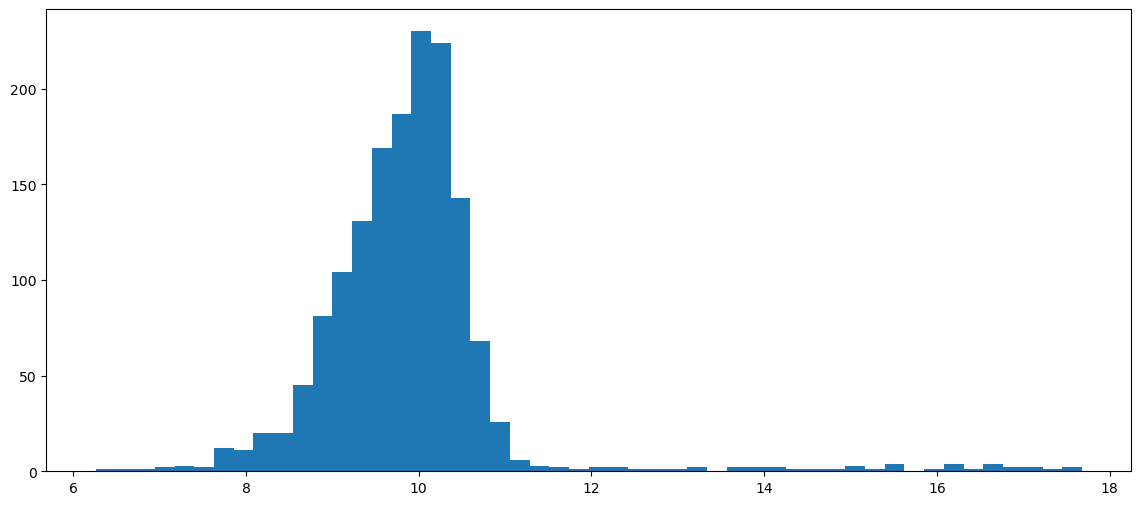

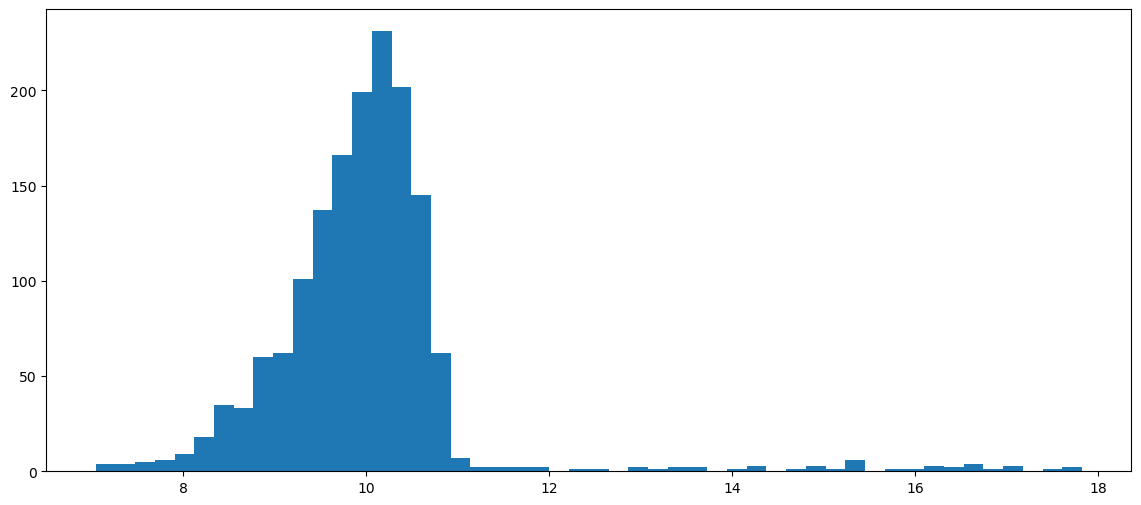

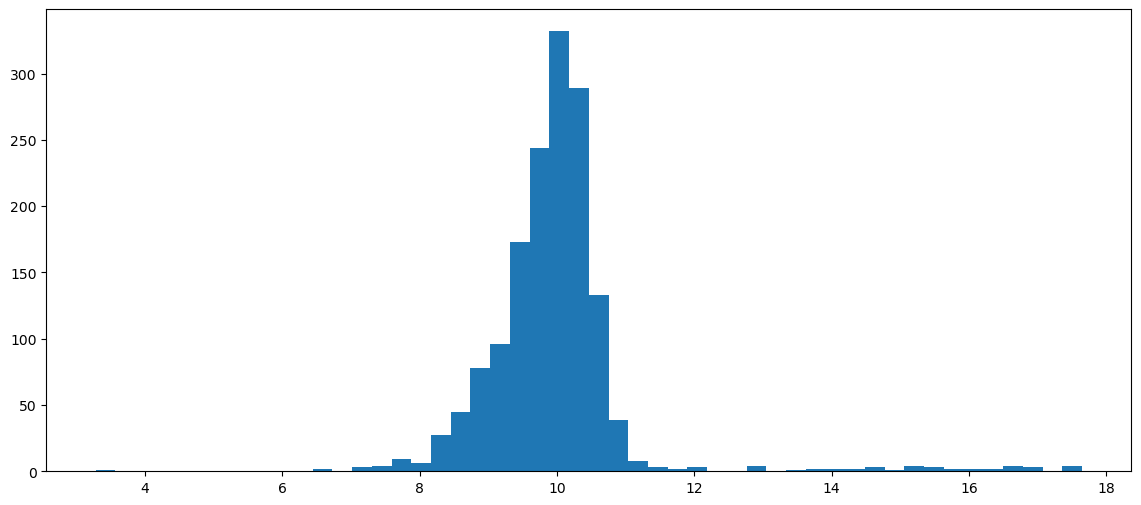

In [5]:
d_abs = np.abs(waterfall_data)
d_log = np.log(d_abs)
for i in range(0, 9):
    plt.hist(d_log[i], bins = 50)
    plt.show()